In [1]:
# importation des modules
import pandas as pd
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# chargement du dataset
df = pd.read_csv('SR2026.csv', encoding='latin-1')

In [3]:
# Affichage d'un echantillon
df.sample(5)

,Creation Date,Status,First 3 Chars of Postal Code,Intersection Street 1,Intersection Street 2,Ward,Service Request Type,Division,Section,Unnamed: 9
366324,10:49.0,In Progress,M6H,NaN,NaN,Davenport (09),Residential Bin Lid Damaged,Solid Waste Management Services,Collections,NaN
65508,07:12.0,Completed,Intersection,Transway Cres,Kennedy Rd,Scarborough Southwest (20),Road Pothole / Road Damage,Transportation Services,Road Operations,NaN
159007,18:48.0,Completed,M6P,NaN,NaN,Parkdale-High Park (04),Residential: Garbage Bin: Missing,Solid Waste Management Services,Collections,NaN
144520,03:33.0,Completed,M1M,NaN,NaN,Scarborough Southwest (20),Residential Bin Lid Damaged,Solid Waste Management Services,Collections,NaN
22615,00:53.0,Completed,M4J,NaN,NaN,Toronto-Danforth (14),Multi-Res / Garbage Front-End / Not Picked Up,Solid Waste Management Services,Collections,NaN


In [4]:
# information du dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 372859 entries, 0 to 372858
Data columns (total 10 columns):
 #   Column                        Non-Null Count   Dtype 
---  ------                        --------------   ----- 
 0   Creation Date                 372859 non-null  object
 1   Status                        372859 non-null  object
 2   First 3 Chars of Postal Code  372859 non-null  object
 3   Intersection Street 1         73179 non-null   object
 4   Intersection Street 2         72622 non-null   object
 5   Ward                          372859 non-null  object
 6   Service Request Type          372851 non-null  object
 7   Division                      372859 non-null  object
 8   Section                       372859 non-null  object
 9   Unnamed: 9                    27088 non-null   object
dtypes: object(10)
memory usage: 28.4+ MB


**Notre dataset concerne Le service 311 Toronto permet aux résidents, aux entreprises et aux visiteurs d'accéder 24 heures sur 24, 
7 jours sur 7, aux services municipaux non urgents, aux programmes et aux renseignements de la Ville de Toronto.**

**Le dataset comprend 10 colonnes que nous allons donner les details a propos de chaque variable**

**Creation Date : date et heure auxquelles une demande de service (SR) est créée et transmise au système de gestion des tâches de la division chargée des demandes de service concernée.**

**Status : Statut actuel de la demande d'intervention**

**Initiated : la demande d'intervention a été reçue et transmise au service municipal compétent pour examen et traitement.
In Progress – Le service municipal concerné travaille actuellement à la résolution de la demande d'intervention.
Canceled – Une demande d'intervention est annulée pour l'une des raisons suivantes : coupure de la communication, le client ne souhaite pas créer de demande d'intervention, le client rappelle pour annuler la demande ou la demande d'intervention a été créée par erreur, etc.
Closed – Le service municipal compétent a examiné la demande du client et a pris les mesures nécessaires pour y répondre.**

**First 3 Chars of Postal Code : Les 3 premiers charactere du code postal de l'adresse de la demande**

**


In [5]:
df.iloc[:, 9].unique()

array([nan, 'Forestry Operations', 'Tree Protection and Plan Review',
       'Forestry and Natural Environment Management',
       ' Disposal & Operations'], dtype=object)

In [6]:
df['Section'].unique()

array(['Toronto Animal Services', 'Investigation Services',
       'Road Operations', 'District Ops', 'TMC', 'Bylaw Enforcement',
       'Collections', ' Climate & Forestry', 'Right of Way (ROW)',
       'Waste Enforcement', 'Business Licensing Enforcement',
       'Operations', 'Parks', 'Traffic Ops',
       'Business Operations Management', 'Parks Enforcement',
       'Litter Operations', 'Traffic Management',
       'Municipal Licensing & Standards - N/A', 'Traffic Safety',
       'Collections and Litter Operations', 'Licensing Team', 'Transfer',
       'District Enforcement', 'Recreation'], dtype=object)

# Traitement des valeurs manquantes

<Axes: >

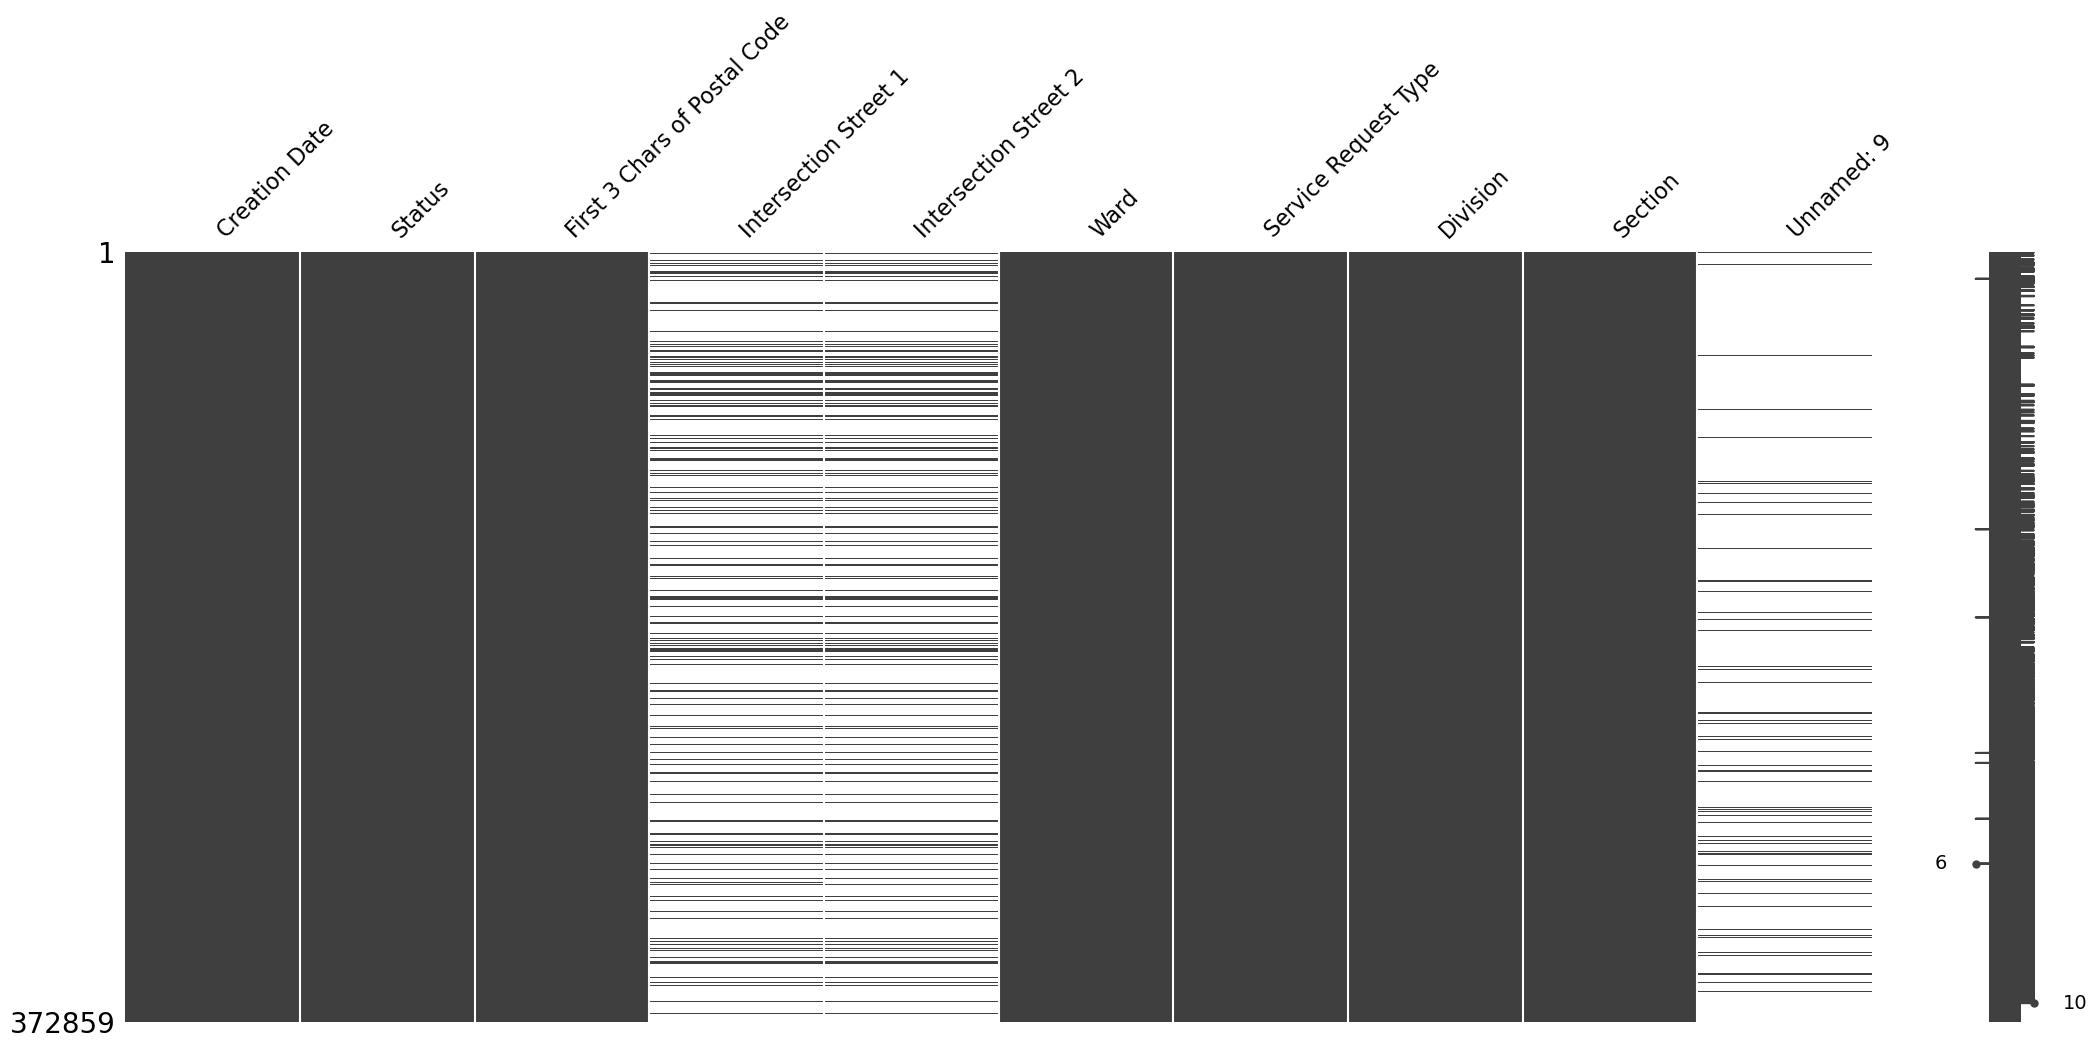

In [7]:
# Identification des valeurs manquantes par missingno
msno.matrix(df)

In [8]:
# Calcule des valeurs manquantes par variable
df.isnull().sum()

Creation Date                        0
Status                               0
First 3 Chars of Postal Code         0
Intersection Street 1           299680
Intersection Street 2           300237
Ward                                 0
Service Request Type                 8
Division                             0
Section                              0
Unnamed: 9                      345771
dtype: int64

In [9]:
df1 = df.drop(df.columns[9], axis=1)

In [10]:
df1

,Creation Date,Status,First 3 Chars of Postal Code,Intersection Street 1,Intersection Street 2,Ward,Service Request Type,Division,Section
0,21:51.0,Completed,M4L,NaN,NaN,Beaches-East York (19),Stray - Confined,Municipal Licensing & Standards,Toronto Animal Services
1,24:48.0,Completed,M1C,NaN,NaN,Scarborough-Rouge Park (25),Property Standards and Maintenance Violations,Municipal Licensing & Standards,Investigation Services
2,27:38.0,Completed,Intersection,Leslie St,Finch Ave E,Don Valley North (17),Clean up Debris on Road,Transportation Services,Road Operations
3,29:23.0,Completed,M2N,NaN,NaN,Willowdale (18),Sewer Service Line-Blocked,Toronto Water,District Ops
4,32:12.0,Closed,Intersection,Lawrence Ave E,Greencrest Crct,Scarborough-Guildwood (24),Traffic Signal Repair,Transportation Services,TMC
...,...,...,...,...,...,...,...,...,...
372854,05:13.0,In Progress,M1W,NaN,NaN,Scarborough-Agincourt (22),Property Standards and Maintenance Violations,Municipal Licensing & Standards,Investigation Services
372855,14:48.0,In Progress,M1K,NaN,NaN,Scarborough Southwest (20),Additional Residential Organic Bin,Solid Waste Management Services,Collections
372856,21:03.0,In Progress,M4C,NaN,NaN,Beaches-East York (19),Residential: Garbage Bin: Exchange to Large,Solid Waste Management Services,Collections
372857,27:10.0,In Progress,M5P,NaN,NaN,Toronto-St. Paul's (12),Water Service Line-No Water,Toronto Water,District Ops


In [11]:
#calculer des valeur manquqntes par lignes
data_na = df1.isnull().sum()
data_na

Creation Date                        0
Status                               0
First 3 Chars of Postal Code         0
Intersection Street 1           299680
Intersection Street 2           300237
Ward                                 0
Service Request Type                 8
Division                             0
Section                              0
dtype: int64

In [12]:
# Le pourcetage des valeurs manquantes
data_na_p=df1[['Intersection Street 1', 'Intersection Street 2', 'Service Request Type']].isnull().mean()*100
data_na_p

Intersection Street 1    80.373546
Intersection Street 2    80.522932
Service Request Type      0.002146
dtype: float64

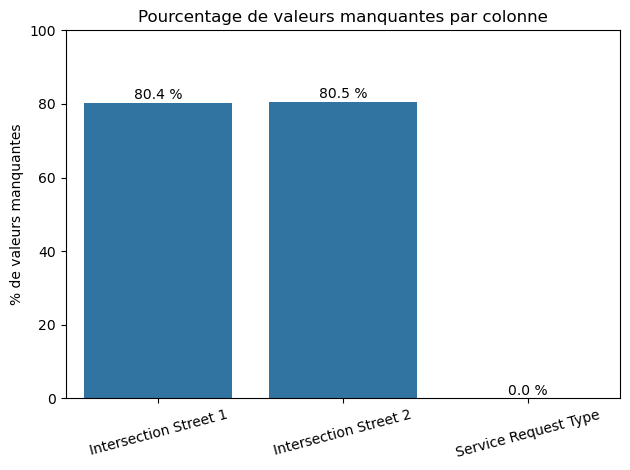

In [13]:
# Diagramme a bar des valeurs manquantes
ax = sns.barplot(x=data_na_p.index, y=data_na_p.values)
ax.set_title("Pourcentage de valeurs manquantes par colonne")
ax.set_ylabel("% de valeurs manquantes")
ax.set_xlabel("")
ax.set_ylim(0, 100)

for i, v in enumerate(data_na_p.values):
    ax.text(i, v + 1, f"{v:.1f} %", ha='center')

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [14]:
# Trie des valeurs manquantes dans les deux variables
df1[(df1['Intersection Street 1'].isnull()) & (df1['Intersection Street 2'].isnull())]

,Creation Date,Status,First 3 Chars of Postal Code,Intersection Street 1,Intersection Street 2,Ward,Service Request Type,Division,Section
0,21:51.0,Completed,M4L,NaN,NaN,Beaches-East York (19),Stray - Confined,Municipal Licensing & Standards,Toronto Animal Services
1,24:48.0,Completed,M1C,NaN,NaN,Scarborough-Rouge Park (25),Property Standards and Maintenance Violations,Municipal Licensing & Standards,Investigation Services
3,29:23.0,Completed,M2N,NaN,NaN,Willowdale (18),Sewer Service Line-Blocked,Toronto Water,District Ops
5,33:42.0,Completed,M8Y,NaN,NaN,Etobicoke-Lakeshore (03),Amplified or Musical Instrument Noise,Municipal Licensing & Standards,Bylaw Enforcement
6,34:02.0,Completed,M6H,NaN,NaN,Davenport (09),Residential Bin Lid Damaged,Solid Waste Management Services,Collections
...,...,...,...,...,...,...,...,...,...
372854,05:13.0,In Progress,M1W,NaN,NaN,Scarborough-Agincourt (22),Property Standards and Maintenance Violations,Municipal Licensing & Standards,Investigation Services
372855,14:48.0,In Progress,M1K,NaN,NaN,Scarborough Southwest (20),Additional Residential Organic Bin,Solid Waste Management Services,Collections
372856,21:03.0,In Progress,M4C,NaN,NaN,Beaches-East York (19),Residential: Garbage Bin: Exchange to Large,Solid Waste Management Services,Collections
372857,27:10.0,In Progress,M5P,NaN,NaN,Toronto-St. Paul's (12),Water Service Line-No Water,Toronto Water,District Ops


In [15]:
# Trie des lignes mqnauantes que dans Intersection Street 2
df1[(~df1['Intersection Street 1'].isnull()) & (df1['Intersection Street 2'].isnull())]

,Creation Date,Status,First 3 Chars of Postal Code,Intersection Street 1,Intersection Street 2,Ward,Service Request Type,Division,Section
807,17:54.0,Completed,Intersection,Moccasin Trl,NaN,Don Valley East (16),Park Property Snow and Ice Clearing,Parks and Recreation,Parks
3168,17:22.0,Completed,Intersection,Cassels Avenue Playground Trl,NaN,Beaches-East York (19),Grass and Sports Field Maintenance in Parks,Parks and Recreation,Parks
5647,57:42.0,Completed,Intersection,Traymore Park Trl,NaN,Parkdale-High Park (04),Park Property Snow and Ice Clearing,Parks and Recreation,Parks
6589,25:36.0,Completed,Intersection,Kennedy - Margdon Parkette Trl,NaN,Parkdale-High Park (04),Park Graffiti Removal,Parks and Recreation,Parks
6803,34:42.0,Completed,Intersection,Dundas St W,NaN,Etobicoke-Lakeshore (03),Road Pothole / Road Damage,Transportation Services,Road Operations
...,...,...,...,...,...,...,...,...,...
361777,06:38.0,Completed,Intersection,Twelfth St,NaN,Etobicoke-Lakeshore (03),Missing/Damaged/Faded Emergency Traffic Signs,Transportation Services,TMC
361872,51:55.0,Cancelled,Intersection,Langside Ave,NaN,York South-Weston (05),Road Water Ponding,Transportation Services,Road Operations
362468,17:20.0,New,Intersection,Beaches Park Trl,NaN,Beaches-East York (19),General Tree Maintenance,Environment,Climate & Forestry
362518,42:21.0,Completed,Intersection,Rozell Rd,NaN,Scarborough-Rouge Park (25),Park Washroom Maintenance,Parks and Recreation,Parks


In [16]:
# Trie des lignes mqnauantes que dans Intersection Street 1
df1[(df1['Intersection Street 1'].isnull()) & ~(df1['Intersection Street 2'].isnull())]

,Creation Date,Status,First 3 Chars of Postal Code,Intersection Street 1,Intersection Street 2,Ward,Service Request Type,Division,Section


In [17]:
df1['Intersection Street 1'].isnull().groupby(df1['Ward']).sum()

Ward
Beaches-East York (19)           16793
Davenport (09)                   18142
Don Valley East (16)              6307
Don Valley North (17)             7740
Don Valley West (15)             11969
Eglinton-Lawrence (08)           14759
Etobicoke Centre (02)            13395
Etobicoke North (01)              8940
Etobicoke-Lakeshore (03)         15197
Humber River-Black Creek (07)     7679
Parkdale-High Park (04)          15171
Scarborough Centre (21)          10746
Scarborough North (23)            7047
Scarborough Southwest (20)       13987
Scarborough-Agincourt (22)        7503
Scarborough-Guildwood (24)        9198
Scarborough-Rouge Park (25)      11140
Spadina-Fort York (10)           10879
Toronto Centre (13)              11220
Toronto-Danforth (14)            18580
Toronto-St. Paul's (12)          14575
University-Rosedale (11)         16844
Unknown                              0
Willowdale (18)                   9469
York Centre (06)                  9715
York South-Weston (0

**Pour identifier le mécanisme des valeurs manquantes des colonnes Intersection Street 1 et Intersection Street 2, nous avons d’abord mesuré leur ampleur : environ 80 % des observations sont manquantes pour chacune de ces deux variables. Nous avons ensuite croisé ces valeurs manquantes avec la variable Ward, afin de vérifier si elles se concentraient dans certains secteurs. La proportion de valeurs manquantes reste comparable d’un secteur à l’autre. Elles ne semblent donc pas liées à la localisation, ce qui est compatible avec un mécanisme de type MCAR (Missing Completely At Random)** 

In [18]:
# Suppression des variables Intersection Street 1 et Intersection Street 2
df1.drop(columns=['Intersection Street 1', 'Intersection Street 2'], inplace=True)

## Traitement des valeurs manquantes de Service Request Type

In [19]:
# Affichage des lignes
df1[df1['Service Request Type'].isnull()]

,Creation Date,Status,First 3 Chars of Postal Code,Ward,Service Request Type,Division,Section
12966,23:40.0,Completed,M1N,Scarborough Southwest (20),NaN,Solid Waste Management Services,Collections and Litter Operations
134258,04:30.0,Completed,M3J,Humber River-Black Creek (07),NaN,Solid Waste Management Services,Collections and Litter Operations
176940,16:23.0,Completed,M6C,Toronto-St. Paul's (12),NaN,Solid Waste Management Services,Collections and Litter Operations
242589,35:40.0,Completed,M6N,York South-Weston (05),NaN,Solid Waste Management Services,Collections and Litter Operations
247411,18:36.0,Completed,M5A,Toronto Centre (13),NaN,Solid Waste Management Services,Collections and Litter Operations
254238,14:53.0,Completed,Intersection,Scarborough North (23),NaN,Solid Waste Management Services,Collections and Litter Operations
274440,00:47.0,Completed,M4P,Don Valley West (15),NaN,Solid Waste Management Services,Collections and Litter Operations
296154,20:06.0,Completed,M6C,Toronto-St. Paul's (12),NaN,Solid Waste Management Services,Collections and Litter Operations


**Nous avons opté pour les suppressions de ces lignes étant donnée qu'elle ne représente que 0.002146% de notre jeu de données**

In [ ]:
# Suppression des lignes où Service Request Type est manquant
df1.dropna(subset=['Service Request Type'], inplace=True)

In [21]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 372859 entries, 0 to 372858
Data columns (total 7 columns):
 #   Column                        Non-Null Count   Dtype 
---  ------                        --------------   ----- 
 0   Creation Date                 372859 non-null  object
 1   Status                        372859 non-null  object
 2   First 3 Chars of Postal Code  372859 non-null  object
 3   Ward                          372859 non-null  object
 4   Service Request Type          372851 non-null  object
 5   Division                      372859 non-null  object
 6   Section                       372859 non-null  object
dtypes: object(7)
memory usage: 19.9+ MB


# Traitement des doublons

In [23]:
# Detection des doublons
df1.duplicated().sum()

np.int64(3410)

In [31]:
#Afficher les lignes en doublons
df1[df1.duplicated(keep=False)]

,Creation Date,Status,First 3 Chars of Postal Code,Ward,Service Request Type,Division,Section
186,23:53.0,Completed,M6E,Davenport (09),Sidewalk Snow Clearing Required,Transportation Services,Road Operations
210,45:25.0,Completed,Intersection,Scarborough Southwest (20),Icy Sidewalk Needs Salting,Transportation Services,Road Operations
221,05:43.0,Completed,M6N,York South-Weston (05),Water Service Line-Check Water Service Box,Toronto Water,District Ops
267,24:12.0,Completed,M9C,Etobicoke Centre (02),Injured - Wildlife,Municipal Licensing & Standards,Toronto Animal Services
313,24:12.0,Completed,M9C,Etobicoke Centre (02),Injured - Wildlife,Municipal Licensing & Standards,Toronto Animal Services
...,...,...,...,...,...,...,...
370119,20:00.0,In Progress,M6S,Parkdale-High Park (04),Request Water Service Turn On,Toronto Water,District Ops
370365,25:44.0,Cancelled,M4J,Toronto-Danforth (14),Residential Oversized/Electronics Item Day Col...,Solid Waste Management Services,Collections
370885,25:33.0,In Progress,M5P,Toronto-St. Paul's (12),Property Standards and Maintenance Violations,Municipal Licensing & Standards,Investigation Services
372018,32:25.0,In Progress,M5A,Toronto Centre (13),Property Standards and Maintenance Violations,Municipal Licensing & Standards,Investigation Services


In [33]:
doublons = df1.duplicated().mean()*100
doublons

np.float64(0.9145548317192289)

**Nous avons dans notre dataset 3410 lignes dupliqués, ce qui représente une 0.9% de notre dataset, nous avons opté pour la suppression de ces lignes étant donnée quel peuvent ajouter un poids en plus par rapport au demande, divison ou section pour éviter de fausser nos analyse la suppression est la meilleur option.**

In [34]:
# Suppression des doublons
df1.drop_duplicates(inplace=True)

In [35]:
# vérification
df1.duplicated().sum()

np.int64(0)

# **Correction des types et les incohérences**

## Conversion de la variable Creation date en Datetime

In [ ]:
import numpy as np

# Aperçu du format brut
df1['Creation Date'].head(10)

In [ ]:
# Les valeurs du type "21:51.0" (mm:ss.0) n'ont pas de date : signe que le CSV
# a été ouvert puis réenregistré dans Excel, qui a tronqué l'horodatage.
format_tronque = df1['Creation Date'].astype(str).str.fullmatch(r'\d{1,2}:\d{2}(\.\d+)?')
print(f"Valeurs sans date : {format_tronque.sum()} ({format_tronque.mean()*100:.1f} %)")

In [ ]:
# Conversion en datetime (les valeurs tronquées deviennent NaT au lieu d'une fausse date)
df1.loc[format_tronque, 'Creation Date'] = None
df1['Creation Date'] = pd.to_datetime(df1['Creation Date'], errors='coerce', format='mixed')

print("Type :", df1['Creation Date'].dtype)
print("Dates non converties :", df1['Creation Date'].isna().sum())
df1['Creation Date'].agg(['min', 'max'])

## Nettoyage des espaces et standardisation des libellés

In [ ]:
# Modalités avec des espaces en trop avant nettoyage
cols_texte = df1.select_dtypes(include=['object', 'string']).columns
for col in cols_texte:
    n = (df1[col].dropna() != df1[col].dropna().str.strip()).sum()
    print(f"{col} : {n} valeurs avec espaces en début/fin")

In [ ]:
# Suppression des espaces en début/fin et des espaces multiples
for col in cols_texte:
    df1[col] = df1[col].str.strip().str.replace(r'\s+', ' ', regex=True)

df1['Section'].unique()

In [ ]:
# Harmonisation des variantes d'orthographe dans Status
df1['Status'] = df1['Status'].replace({'Canceled': 'Cancelled'})
df1['Status'].value_counts()

## Contrôle des modalités rares

In [ ]:
def modalites_rares(serie, seuil=0.5):
    """Retourne les modalités qui représentent moins de `seuil` % des lignes."""
    pct = serie.value_counts(normalize=True) * 100
    return pct[pct < seuil].round(3)

print("Status - modalités rares :")
print(modalites_rares(df1['Status']))

In [ ]:
print("Nombre de Ward :", df1['Ward'].nunique())
print("\nWard - modalités rares :")
print(modalites_rares(df1['Ward']))
print("\nLignes avec Ward = 'Unknown' :", (df1['Ward'] == 'Unknown').sum())

In [ ]:
# Répartition des demandes par Ward
df1['Ward'].value_counts().plot(kind='barh', figsize=(8, 8))
plt.xlabel("Nombre de demandes")
plt.title("Demandes par Ward")
plt.tight_layout()
plt.show()

## Vérification de la cohérence chronologique

In [ ]:
dates = df1['Creation Date']

print("Période couverte :", dates.min(), "→", dates.max())
print("Dates dans le futur :", (dates > pd.Timestamp.now()).sum())
print("Dates hors 2026 :", (dates.notna() & (dates.dt.year != 2026)).sum())
print("Enregistrements triés par date :", dates.dropna().is_monotonic_increasing)

In [ ]:
# Cohérence statut / date : une demande encore 'New' ou 'Initiated' très ancienne est suspecte
age_jours = (dates.max() - dates).dt.days
df1.assign(age_jours=age_jours).groupby('Status')['age_jours'].describe().round(1)

In [ ]:
# Volume de demandes par jour : repère les trous ou les pics anormaux
df1.set_index('Creation Date').resample('D').size().plot(figsize=(12, 4))
plt.ylabel("Nombre de demandes")
plt.title("Demandes par jour")
plt.tight_layout()
plt.show()

## Création des variables dérivées

In [ ]:
jours = ['Lundi', 'Mardi', 'Mercredi', 'Jeudi', 'Vendredi', 'Samedi', 'Dimanche']

df1['Mois'] = df1['Creation Date'].dt.month
df1['Jour semaine'] = df1['Creation Date'].dt.dayofweek.map(dict(enumerate(jours)))
df1['Heure'] = df1['Creation Date'].dt.hour

# Type de localisation : la demande porte sur une intersection ou sur une adresse
df1['Type localisation'] = np.where(
    df1['First 3 Chars of Postal Code'] == 'Intersection', 'Intersection', 'Adresse'
)

df1[['Creation Date', 'Mois', 'Jour semaine', 'Heure', 'Type localisation']].head()

In [ ]:
df1['Type localisation'].value_counts(normalize=True).mul(100).round(1)

## Vérification finale du jeu de données

In [ ]:
df1.info()
print("\nValeurs manquantes :")
print(df1.isnull().sum())
print("\nDoublons :", df1.duplicated().sum())

In [ ]:
# Sauvegarde du jeu de données propre pour l'AED
df1.to_csv('SR2026_propre.csv', index=False)